# Lab 9 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab09.py`
and draws the three figures for your report. It therefore only runs once your implementation
is correct. Export the figures (right-click, or `plt.savefig`) and embed them in `report.pdf`.

In [2]:
import sys
sys.path.insert(0, '../src')
import matplotlib.pyplot as plt
import numpy as np
import torch
import lab09

data = lab09.load_data('../data/lab09_ring.npz')
art = {}                                # run_experiment stores samples/curves here
rng = torch.Generator().manual_seed(lab09.SEED)
metrics = lab09.run_experiment(data, rng, out=art)   # about 10 s on CPU
{k: v for k, v in metrics.items() if not isinstance(v, list)}

{'n_train': 2000,
 'n_gen': 2000,
 'coverage_gan': 6,
 'coverage_ddpm': 8,
 'hq_gan': 0.942,
 'hq_ddpm': 0.8585,
 'd_loss_final': 1.3181,
 'g_loss_final': 1.0039,
 'ddpm_loss_final': 0.2443,
 'gan_sample_seconds': 0.0004,
 'ddpm_sample_seconds': 0.1315}

## Plot 1 — Real data vs GAN samples vs DDPM samples

Three scatter panels side by side, same axis limits. Mark the true `mode_centers`
(e.g., black crosses) on every panel: a cross with no cloud around it is a mode
that model did not produce.

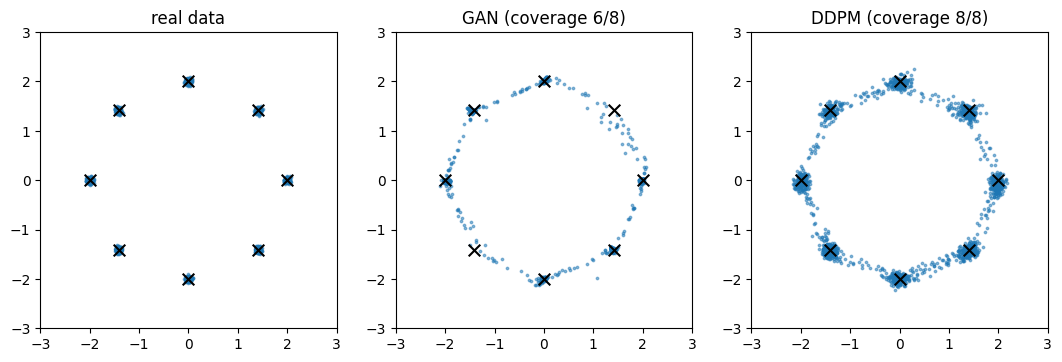

In [3]:
panels = [('real data', data['samples']),
          (f"GAN (coverage {metrics['coverage_gan']}/8)", art['samples_gan']),
          (f"DDPM (coverage {metrics['coverage_ddpm']}/8)", art['samples_ddpm'])]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, (title, pts) in zip(axes, panels):
    ax.scatter(pts[:, 0], pts[:, 1], s=3, alpha=0.5)
    ax.scatter(data['mode_centers'][:, 0], data['mode_centers'][:, 1],
               marker='x', s=70, c='black', linewidths=1.5, zorder=3)
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_aspect('equal')
    ax.set_title(title)
plt.savefig('fig1.png', dpi=150, bbox_inches='tight')
plt.show()

## Plot 2 — Training loss curves

Left: `metrics['gan_d_curve']` and `metrics['gan_g_curve']` (one point per
`LOG_EVERY` = 100 steps). Right: `metrics['ddpm_curve']`. Note how differently
the two trainings "look" while running.

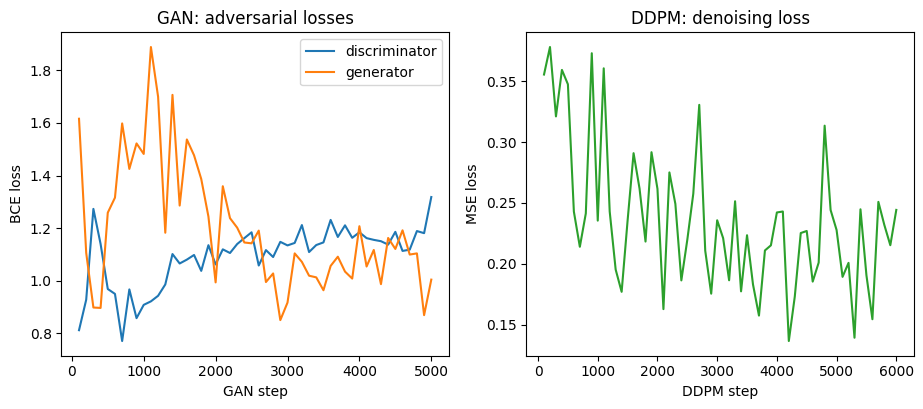

In [4]:
steps_gan = [(i+1) * lab09.LOG_EVERY for i in range(len(metrics['gan_d_curve']))]
steps_ddpm = [(i+1) * lab09.LOG_EVERY for i in range(len(metrics['ddpm_curve']))]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(steps_gan, metrics['gan_d_curve'], label='discriminator')
axes[0].plot(steps_gan, metrics['gan_g_curve'], label='generator')
axes[0].set_xlabel('GAN step')
axes[0].set_ylabel('BCE loss')
axes[0].set_title('GAN: adversarial losses')
axes[0].legend()

axes[1].plot(steps_ddpm, metrics['ddpm_curve'], color='tab:green')
axes[1].set_xlabel('DDPM step')
axes[1].set_ylabel('MSE loss')
axes[1].set_title('DDPM: denoising loss')
plt.savefig('fig2.png', dpi=150, bbox_inches='tight')
plt.show()

## Plot 3 — Per-mode sample share

Grouped bars: `metrics['gan_mode_shares']` vs `metrics['ddpm_mode_shares']` for
modes 0–7, with a horizontal line at `lab09.MODE_SHARE_MIN`. Bars below the
line are the uncovered modes.

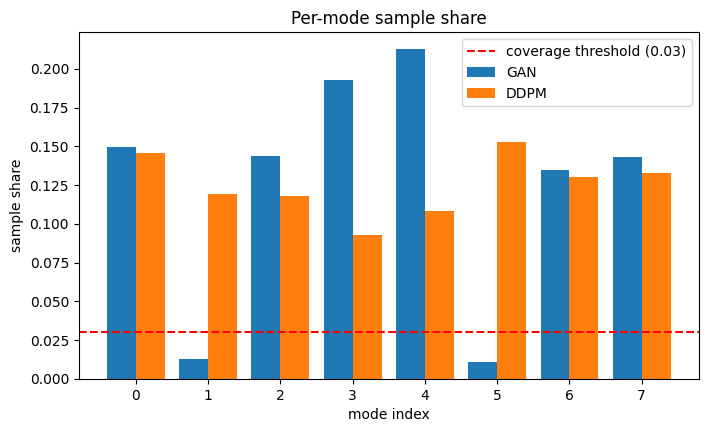

coverage — GAN 6/8, DDPM 8/8


In [5]:
idx = np.arange(8)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(idx-0.2, metrics['gan_mode_shares'], width=0.4, label='GAN')
ax.bar(idx+0.2, metrics['ddpm_mode_shares'], width=0.4, label='DDPM')
ax.axhline(lab09.MODE_SHARE_MIN, linestyle='--', color='red',
           label=f'coverage threshold ({lab09.MODE_SHARE_MIN})')
ax.set_xticks(idx)
ax.set_xlabel('mode index')
ax.set_ylabel('sample share')
ax.set_title('Per-mode sample share')
ax.legend()
plt.savefig('fig3.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"coverage — GAN {metrics['coverage_gan']}/8, DDPM {metrics['coverage_ddpm']}/8")